In [1]:
"""
Arctic Dipole (AD) Monthly Index
================================================================================
Computes the monthly Arctic Dipole (AD) index from ERA5 MSLP using the
standard literature method (Wu, Wang & Walsh, 2006; Watanabe, Ikeda &
Wakatsuchi, 2006; Overland & Wang, 2010): area-weighted EOF of MSLP anomalies
poleward of 70N, AD = EOF2 (second mode), sign-fixed so +AD = high pressure
over Canadian Arctic/Beaufort/Greenland, low pressure over Siberia/Kara-Laptev,
normalized to unit standard deviation.

REUSES the area-weighted EOF machinery (area_weighted_eof_matrix,
north_rule_of_thumb, monthly_anomaly_da) verbatim from
compute_eof_analysis_era5.ipynb -- same SVD-based approach, no external
`eofs` package dependency. AD is computed FULL-YEAR (all 12 months), unlike
that notebook's winter-only (Oct-Apr) circulation EOFs, per the standard AD
definition and per instruction.

DELIBERATE DEPARTURE from compute_eof_analysis_era5.ipynb's convention: that
notebook leaves PC sign exactly as SVD returns it (unsupervised circulation
modes, no externally "correct" sign). AD is different -- its sign is part of
its literature definition, not an arbitrary SVD artifact -- so this notebook
DOES sign-fix, deliberately and documented, against a Canada-box vs
Siberia-box loading comparison.

Outputs
-------
  ./outputs/processed_data/arctic_dipole/arctic_dipole_monthly.csv
  ./outputs/processed_data/arctic_dipole/arctic_dipole_eof_result_{RUN_TAG}.npz
  ./outputs/figures/arctic_dipole/arctic_dipole_spatial_pattern_{RUN_TAG}.png
  ./outputs/figures/arctic_dipole/arctic_dipole_timeseries_{RUN_TAG}.png
  ./outputs/methods/arctic_dipole_methodology.md
  AD written as a new variable into all_climate_indices.nc

References
----------
Wu, B., Wang, J., & Walsh, J. E. (2006). Dipole anomaly in the Arctic
atmosphere and its influences on sea ice motion. Global and Planetary
Change, 52(1-4), 33-51.
Watanabe, M., Ikeda, M., & Wakatsuchi, M. (2006). A dipole anomaly in the
winter Arctic atmosphere. Journal of Climate, 19(9), 1636-1645.
Overland, J. E., & Wang, M. (2010). Large-scale atmospheric circulation
changes are associated with the recent loss of Arctic sea ice. Tellus A,
62(1), 1-9.
North, G. R., Bell, T. L., Cahalan, R. F., & Moeng, F. J. (1982). Sampling
errors in the estimation of empirical orthogonal functions. Monthly Weather
Review, 110, 699-706.

Author: Chris Barrell
"""

import sys
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy import stats

warnings.filterwarnings('ignore')

sys.path.append('..')
from utils.logger import (setup_logger, log_data_loading, log_processing_step,
                          log_output_file, log_completion, log_error)

logger = setup_logger('compute_arctic_dipole', config_path='../config.yaml')
start_time = datetime.now()


INFO     | ======================================================================
INFO     | Starting analysis: compute_arctic_dipole
INFO     | Log file: outputs/logs/compute_arctic_dipole_20260916_130127.log
INFO     | Timestamp: 2026-09-16 13:01:27
INFO     | ======================================================================


## Configuration

In [2]:
# ==== Paths ====
ERA5_MSLP_NC = Path('../../era5/monthly_average_mslp_global.nc')
CLIMATE_NC = Path('./outputs/processed_data/climate_indices/all_climate_indices.nc')

OUT_DATA = Path('./outputs/processed_data/arctic_dipole')
OUT_FIG = Path('./outputs/figures/arctic_dipole')
OUT_METH = Path('./outputs/methods')
for d in (OUT_DATA, OUT_FIG, OUT_METH):
    d.mkdir(parents=True, exist_ok=True)

SAVE_DATA = True
DPI = 600
RUN_TAG = 'ad_v1'

# ==== Domain ====
LAT_DIM, LON_DIM, TIME_DIM = 'latitude', 'longitude', 'valid_time'
AD_LAT_RANGE = (70, 90)          # deg N poleward cutoff (Wu et al. 2006)

# ==== EOF configuration ====
N_MODES = 3           # EOF1-3; AD = EOF2. EOF3 kept only to check North's-rule
                       # separability either side of EOF2, not reported as an index.
AD_MODE_IDX = 1        # EOF2, 0-indexed
DETREND = False         # AD is a circulation-variability index, not a trend index --
                       # standard AD literature does not detrend before EOF.

# ==== Sign convention (Wu et al. 2006): +AD = high pressure over Canadian
# Arctic/Beaufort/Greenland, low pressure over Siberia/Kara-Laptev.
# NOTE: compute_eof_analysis_era5.ipynb deliberately does NOT post-hoc sign-align
# PCs (its EOFs are unsupervised circulation modes). AD's sign IS part of its
# literature definition, so sign-fixing here is a deliberate, documented
# departure from that notebook's convention -- see header docstring.
# Longitude in this ERA5 file runs 0-360 (GRIB convention), not -180/180.
SIGN_BOX_POSITIVE = {'lat': (75, 85), 'lon': (210, 300)}   # Canada/Beaufort/Greenland (150W-60W)
SIGN_BOX_NEGATIVE = {'lat': (75, 85), 'lon': (60, 150)}    # Siberia/Kara-Laptev (60E-150E)


## Section 1 -- Load ERA5 MSLP, subset to AD domain (70-90N, all longitudes)

In [3]:
log_processing_step(logger, 'Loading ERA5 MSLP and subsetting to AD domain')

if not ERA5_MSLP_NC.exists():
    raise FileNotFoundError(f'{ERA5_MSLP_NC} not found.')

ds = xr.open_dataset(ERA5_MSLP_NC)
if 'msl' not in ds.data_vars:
    raise KeyError(f"'msl' not in {ERA5_MSLP_NC} -- available: {sorted(ds.data_vars)}")

# valid_time -> time, matching this project's usual time-dimension name elsewhere
ds = ds.rename({TIME_DIM: 'time'})
TIME_DIM = 'time'

lat_vals = ds[LAT_DIM].values
lat_decreasing = lat_vals[0] > lat_vals[-1]
lat_slice = (slice(AD_LAT_RANGE[1], AD_LAT_RANGE[0]) if lat_decreasing
            else slice(AD_LAT_RANGE[0], AD_LAT_RANGE[1]))

msl = ds['msl'].sel({LAT_DIM: lat_slice}) / 100.0   # Pa -> hPa
logger.info(f"MSLP subset: {msl.sizes[TIME_DIM]} months, "
           f"{msl.sizes[LAT_DIM]}x{msl.sizes[LON_DIM]} gridpoints, "
           f"lat {float(msl[LAT_DIM].min()):.1f} to {float(msl[LAT_DIM].max()):.1f} N, "
           f"{str(msl[TIME_DIM].values[0])[:7]} to {str(msl[TIME_DIM].values[-1])[:7]}")


INFO     | Processing: Loading ERA5 MSLP and subsetting to AD domain
INFO     | MSLP subset: 920 months, 81x1440 gridpoints, lat 70.0 to 90.0 N, 1950-01 to 2026-08


## Section 2 -- Deseasonalize

Whole-record monthly climatology removed, all 12 months (AD is full-year, unlike this project's winter-restricted EOF work). `monthly_anomaly_da` reused verbatim from `compute_eof_analysis_era5.ipynb`.

In [4]:
def monthly_anomaly_da(da):
    """Whole-record monthly climatology removed. Reused verbatim from
    compute_eof_analysis_era5.ipynb."""
    return da.groupby(f'{TIME_DIM}.month') - da.groupby(f'{TIME_DIM}.month').mean(TIME_DIM)


anom = monthly_anomaly_da(msl)
logger.info("Deseasonalized: whole-record monthly climatology removed, all 12 months retained "
           "(AD is a full-year index per Wu et al. 2006).")


INFO     | Deseasonalized: whole-record monthly climatology removed, all 12 months retained (AD is a full-year index per Wu et al. 2006).


## Section 3 -- Area-weighted EOF via SVD

`area_weighted_eof_matrix` and `north_rule_of_thumb` reused verbatim from `compute_eof_analysis_era5.ipynb` -- same sqrt(cos(latitude)) weighting, plain `np.linalg.svd`, no `eofs` package dependency.

In [5]:
lat_v = anom[LAT_DIM].values
lon_v = anom[LON_DIM].values
times_v = pd.to_datetime(anom[TIME_DIM].values)
shape2d = (len(lat_v), len(lon_v))

combined = anom.values.reshape(len(times_v), -1)
finite_cols = np.isfinite(combined).all(axis=0)
combined = combined[:, finite_cols]
n_dropped = int((~finite_cols).sum())
if n_dropped:
    logger.warning(f"{n_dropped} of {len(finite_cols)} spatial columns dropped (non-finite at "
                   f"some month) -- unexpected for MSLP; check for missing months if large.")
logger.info(f"Field matrix: {combined.shape[0]} months x {combined.shape[1]} spatial columns")

lat_grid = np.repeat(lat_v, len(lon_v))[finite_cols]
lon_grid = np.tile(lon_v, len(lat_v))[finite_cols]


def area_weighted_eof_matrix(combined, lat_for_each_col, n_modes=N_MODES):
    """Reused verbatim from compute_eof_analysis_era5.ipynb. combined: (time, space),
    already anomalised (and optionally detrended). Area weighting sqrt(cos(lat))."""
    w = np.sqrt(np.cos(np.deg2rad(lat_for_each_col)))
    weighted = combined * w[None, :]
    U, S, Vt = np.linalg.svd(weighted, full_matrices=False)
    n_t = combined.shape[0]
    eigenvalues = S**2 / (n_t - 1)
    var_frac = eigenvalues / eigenvalues.sum()
    pcs = U[:, :n_modes] * S[:n_modes]
    eofs = Vt[:n_modes]
    return eofs, pcs, var_frac[:n_modes], eigenvalues


def north_rule_of_thumb(eigenvalues, n_t):
    """Reused verbatim from compute_eof_analysis_era5.ipynb."""
    errors = eigenvalues * np.sqrt(2.0 / n_t)
    separable = []
    for i in range(len(eigenvalues) - 1):
        gap = eigenvalues[i] - eigenvalues[i + 1]
        separable.append(bool(gap > (errors[i] + errors[i + 1])))
    return errors, separable


eofs_arr, pcs, var_frac, eigenvalues = area_weighted_eof_matrix(combined, lat_grid, n_modes=N_MODES)
n_t_eof = combined.shape[0]

# NOTE: area_weighted_eof_matrix returns the FULL eigenvalue spectrum from the SVD
# (length min(n_time, n_space) -- here that's all n_time months, since space >> time),
# not sliced to N_MODES -- same behaviour as compute_eof_analysis_era5.ipynb. Slice
# here before the separability check, or north_rule_of_thumb evaluates and logs a
# pairwise comparison for every one of those (hundreds of irrelevant EOFx-vs-EOFy
# lines) instead of just the N_MODES-1 comparisons that are actually meaningful.
eigenvalues_for_check = eigenvalues[:N_MODES]
errors, separable = north_rule_of_thumb(eigenvalues_for_check, n_t_eof)

logger.info(f"Variance explained EOF1-{N_MODES}: {[f'{100*v:.1f}%' for v in var_frac]}")
for i, sep in enumerate(separable):
    logger.info(f"  EOF{i+1} vs EOF{i+2}: "
               f"{'separable' if sep else 'NOT separable -- degenerate pair'} (North et al. 1982)")

if len(separable) > 0 and not separable[0]:
    logger.warning("EOF1 vs EOF2 NOT separable by North's rule -- AD (EOF2) may not be a "
                   "well-defined mode distinct from EOF1 in this domain/period. Treat with caution.")


INFO     | Field matrix: 920 months x 116640 spatial columns
INFO     | Variance explained EOF1-3: ['53.2%', '16.6%', '12.1%']
INFO     |   EOF1 vs EOF2: separable (North et al. 1982)
INFO     |   EOF2 vs EOF3: separable (North et al. 1982)


## Section 4 -- Extract AD = EOF2: normalize, sign-fix

PC2 normalized to unit standard deviation. Sign fixed against the Canada/Beaufort/Greenland vs Siberia/Kara-Laptev box comparison -- see header docstring for why this deliberately departs from `compute_eof_analysis_era5.ipynb`'s no-alignment convention.

In [6]:
pc2_raw = pcs[:, AD_MODE_IDX]
eof2_raw = eofs_arr[AD_MODE_IDX]

# ---- Normalize PC2 to unit standard deviation (Wu et al. 2006 convention) ----
pc2 = (pc2_raw - pc2_raw.mean()) / pc2_raw.std()
logger.info(f"PC2 normalized: mean={pc2.mean():.4f} (expect ~0), std={pc2.std():.4f} (expect 1.0)")


def box_mean_loading(eof_vec, lat_grid, lon_grid, box):
    m = ((lat_grid >= box['lat'][0]) & (lat_grid <= box['lat'][1]) &
        (lon_grid >= box['lon'][0]) & (lon_grid <= box['lon'][1]))
    if m.sum() == 0:
        raise ValueError(f"Sign-check box {box} matched zero gridpoints -- check lon convention "
                         f"(0-360 here, not -180/180).")
    return float(eof_vec[m].mean()), int(m.sum())


pos_mean, n_pos = box_mean_loading(eof2_raw, lat_grid, lon_grid, SIGN_BOX_POSITIVE)
neg_mean, n_neg = box_mean_loading(eof2_raw, lat_grid, lon_grid, SIGN_BOX_NEGATIVE)
logger.info(f"Sign check: Canada/Beaufort/Greenland box mean loading = {pos_mean:+.4f} ({n_pos} pts), "
           f"Siberia/Kara-Laptev box mean loading = {neg_mean:+.4f} ({n_neg} pts)")

flip = pos_mean < neg_mean
if flip:
    logger.info("Flipping sign: SVD-returned EOF2 has the Canada side negative -- flipping both "
               "PC2 and EOF2 to match the Wu et al. (2006) convention (+AD = high "
               "Canada/Greenland, low Siberia).")
    pc2 = -pc2
    eof2 = -eof2_raw
    pos_mean, neg_mean = -pos_mean, -neg_mean
else:
    logger.info("Sign already matches convention -- no flip needed.")
    eof2 = eof2_raw

AD_index = pd.Series(pc2, index=times_v, name='AD')
logger.info(f"AD index: {len(AD_index)} months, {AD_index.index.min():%Y-%m} to "
           f"{AD_index.index.max():%Y-%m}")


INFO     | PC2 normalized: mean=0.0000 (expect ~0), std=1.0000 (expect 1.0)
INFO     | Sign check: Canada/Beaufort/Greenland box mean loading = -0.0031 (14801 pts), Siberia/Kara-Laptev box mean loading = +0.0034 (14801 pts)
INFO     | Flipping sign: SVD-returned EOF2 has the Canada side negative -- flipping both PC2 and EOF2 to match the Wu et al. (2006) convention (+AD = high Canada/Greenland, low Siberia).
INFO     | AD index: 920 months, 1950-01 to 2026-08


## Section 5 -- Self-tests

In [7]:
def _run_self_tests():
    # --- Test 1: EOF recovery on synthetic data (same design as
    # compute_eof_analysis_era5.ipynb Section 8) ---
    rng = np.random.default_rng(0)
    lat_test = np.linspace(70, 90, 20)
    lon_test = np.linspace(0, 359, 40)
    LO_t, LA_t = np.meshgrid(lon_test, lat_test)
    n_t_test = 200

    true_pattern = (np.exp(-(((LO_t - 250) / 40) ** 2 + ((LA_t - 80) / 6) ** 2)) -
                    np.exp(-(((LO_t - 100) / 40) ** 2 + ((LA_t - 80) / 6) ** 2)))
    true_pattern -= true_pattern.mean()
    true_pc = rng.normal(size=n_t_test)

    field_test = true_pc[:, None, None] * true_pattern[None, :, :] * 5.0
    field_test += rng.normal(scale=0.3, size=(n_t_test, len(lat_test), len(lon_test)))
    combined_test = field_test.reshape(n_t_test, -1)
    lat_grid_test = np.repeat(lat_test, len(lon_test))
    lon_grid_test = np.tile(lon_test, len(lat_test))

    eofs_t, pcs_t, var_frac_t, eig_t = area_weighted_eof_matrix(combined_test, lat_grid_test, n_modes=3)
    r_pattern = np.corrcoef(eofs_t[0], true_pattern.ravel())[0, 1]
    r_pc = np.corrcoef(pcs_t[:, 0], true_pc)[0, 1]
    print(f"TEST 1  EOF recovery: spatial r={abs(r_pattern):.2f}, temporal r={abs(r_pc):.2f}")
    assert abs(r_pattern) > 0.9 and abs(r_pc) > 0.9, "EOF failed to recover a planted dominant pattern"

    # --- Test 2: sign-FIX LOGIC (decision + flip), not just the raw SVD sign ---
    # SVD/EOF sign is arbitrary -- eofs_t[0] is NOT guaranteed to come back
    # Canada-positive just because the planted pattern was built that way (it may
    # legitimately come back negated). The thing that must be correct is the
    # decision-and-flip logic itself: whichever sign SVD happens to return, applying
    # the same flip-if-needed rule used in Section 4 must yield a Canada-positive
    # result. Testing the raw SVD sign directly (as an earlier version of this test
    # did) is not a valid test, since that sign is not fixed by anything.
    box_pos = {'lat': (75, 85), 'lon': (210, 300)}
    box_neg = {'lat': (75, 85), 'lon': (60, 150)}
    pos_raw, _ = box_mean_loading(eofs_t[0], lat_grid_test, lon_grid_test, box_pos)
    neg_raw, _ = box_mean_loading(eofs_t[0], lat_grid_test, lon_grid_test, box_neg)
    flip_needed_t = pos_raw < neg_raw
    eof_fixed_t = -eofs_t[0] if flip_needed_t else eofs_t[0]
    pos_fixed, _ = box_mean_loading(eof_fixed_t, lat_grid_test, lon_grid_test, box_pos)
    neg_fixed, _ = box_mean_loading(eof_fixed_t, lat_grid_test, lon_grid_test, box_neg)
    print(f"TEST 2  sign-fix logic: raw pos={pos_raw:+.3f} neg={neg_raw:+.3f} "
         f"(SVD sign is arbitrary -- this may legitimately be either orientation), "
         f"flip_needed={flip_needed_t}, post-fix pos={pos_fixed:+.3f} neg={neg_fixed:+.3f}")
    assert pos_fixed > neg_fixed, \
        "Sign-fix logic failed to orient the planted Canada-positive pattern correctly"

    # --- Test 3: PC normalization ---
    test_pc = rng.normal(loc=5, scale=2.3, size=500)
    test_pc_norm = (test_pc - test_pc.mean()) / test_pc.std()
    assert abs(test_pc_norm.mean()) < 1e-8 and abs(test_pc_norm.std() - 1.0) < 1e-8
    print("TEST 3  PC normalization: mean~0, std=1 -- confirmed")

    print("\nAll self-tests passed.")


_run_self_tests()


TEST 1  EOF recovery: spatial r=0.99, temporal r=1.00
TEST 2  sign-fix logic: raw pos=-0.062 neg=+0.061 (SVD sign is arbitrary -- this may legitimately be either orientation), flip_needed=True, post-fix pos=+0.062 neg=-0.061
TEST 3  PC normalization: mean~0, std=1 -- confirmed

All self-tests passed.


## Section 6 -- Save outputs: monthly CSV, EOF cache, append to `all_climate_indices.nc`

In [8]:
log_processing_step(logger, 'Saving outputs')

if SAVE_DATA:
    # ---- Monthly AD index CSV ----
    ad_df = AD_index.reset_index()
    ad_df.columns = ['time', 'AD']
    ad_csv = OUT_DATA / 'arctic_dipole_monthly.csv'
    ad_df.to_csv(ad_csv, index=False)
    log_output_file(logger, 'csv', ad_csv)

    # ---- Spatial EOF2 pattern + explained variance, cached for later reuse ----
    np.savez(OUT_DATA / f'arctic_dipole_eof_result_{RUN_TAG}.npz',
             pc2=pc2, eof2=eof2, var_frac=var_frac, eigenvalues=eigenvalues,
             times_v=times_v.values.astype('datetime64[ns]').astype(np.int64),
             lat_v=lat_v, lon_v=lon_v, finite_cols=finite_cols, shape2d=np.array(shape2d),
             separable=np.array(separable), flipped=flip)
    logger.info(f"EOF2 spatial pattern + full result cached: "
               f"{OUT_DATA / f'arctic_dipole_eof_result_{RUN_TAG}.npz'}")

    # ---- Append to all_climate_indices.nc ----
    # ASSUMPTION (verify the logged overlap count below): the nc file's time
    # coordinate is named 'time' and uses the same monthly timestamp convention
    # (e.g. month-start) as the indices already in it. A low overlap count means
    # that assumption is wrong and should be checked before trusting the result.
    if not CLIMATE_NC.exists():
        raise FileNotFoundError(f"{CLIMATE_NC} not found -- cannot append AD to it.")

    ds_clim = xr.open_dataset(CLIMATE_NC)
    ds_clim.load()
    ds_clim.close()

    if 'AD' in ds_clim.data_vars:
        logger.warning("'AD' already exists in all_climate_indices.nc -- overwriting.")

    ad_da = xr.DataArray(AD_index.values, dims=['time'],
                         coords={'time': AD_index.index.values}, name='AD')
    ad_da_aligned = ad_da.reindex(time=ds_clim['time'].values)
    n_overlap = int(np.isfinite(ad_da_aligned.values).sum())
    logger.info(f"AD aligned to all_climate_indices.nc time axis: {n_overlap} of "
               f"{ds_clim.sizes['time']} timesteps matched (of {len(AD_index)} AD months computed).")
    if n_overlap == 0:
        raise ValueError("Zero timesteps matched between AD and all_climate_indices.nc's time "
                         "axis -- check the time coordinate format (e.g. month-start vs "
                         "mid-month) before proceeding. NOT writing an all-NaN AD column.")

    ds_clim['AD'] = ad_da_aligned
    ds_clim.to_netcdf(CLIMATE_NC)
    log_output_file(logger, 'netcdf', CLIMATE_NC)
    logger.info(f"AD written into {CLIMATE_NC} ({n_overlap} valid months).")


INFO     | Processing: Saving outputs
INFO     | Created csv: arctic_dipole_monthly.csv
INFO     | EOF2 spatial pattern + full result cached: outputs/processed_data/arctic_dipole/arctic_dipole_eof_result_ad_v1.npz
INFO     | AD aligned to all_climate_indices.nc time axis: 920 of 2112 timesteps matched (of 920 AD months computed).
INFO     | Created netcdf: all_climate_indices.nc
INFO     | AD written into outputs/processed_data/climate_indices/all_climate_indices.nc (920 valid months).


## Section 7 -- Verification plots

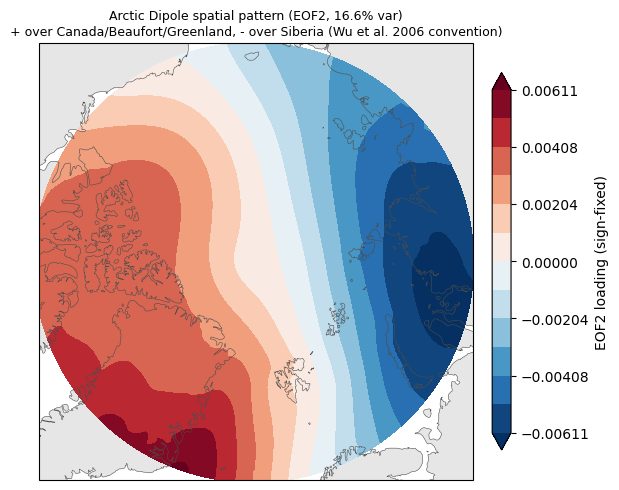

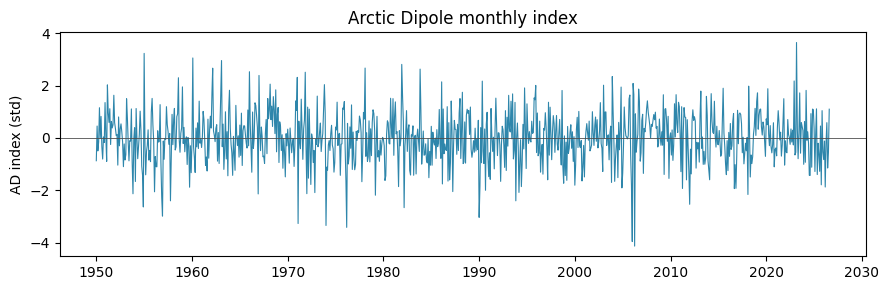

In [9]:
def unmask_reshape(vec, finite_mask, shape2d):
    full = np.full(finite_mask.shape, np.nan)
    full[finite_mask] = vec
    return full.reshape(shape2d)


loading_map = unmask_reshape(eof2, finite_cols, shape2d)

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw={'projection': ccrs.NorthPolarStereo()})
ax.set_extent([-180, 180, AD_LAT_RANGE[0], 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor='0.9', zorder=0)
ax.coastlines(resolution='50m', linewidth=0.4, color='0.3')
lim = np.nanpercentile(np.abs(loading_map), 98) or 1.0
im = ax.contourf(lon_v, lat_v, loading_map, levels=np.linspace(-lim, lim, 13),
                 cmap='RdBu_r', extend='both', transform=ccrs.PlateCarree())
plt.colorbar(im, ax=ax, fraction=0.04, pad=0.04, label='EOF2 loading (sign-fixed)')
ax.set_title(f'Arctic Dipole spatial pattern (EOF2, {100*var_frac[AD_MODE_IDX]:.1f}% var)\n'
            f'+ over Canada/Beaufort/Greenland, - over Siberia (Wu et al. 2006 convention)',
            fontsize=9)
fig.tight_layout()
fig.savefig(OUT_FIG / f'arctic_dipole_spatial_pattern_{RUN_TAG}.png', dpi=DPI, bbox_inches='tight')
plt.show()

fig2, ax2 = plt.subplots(figsize=(9, 3))
ax2.plot(AD_index.index, AD_index.values, lw=0.8, color='#2E86AB')
ax2.axhline(0, color='0.3', lw=0.6)
ax2.set_ylabel('AD index (std)')
ax2.set_title('Arctic Dipole monthly index')
fig2.tight_layout()
fig2.savefig(OUT_FIG / f'arctic_dipole_timeseries_{RUN_TAG}.png', dpi=DPI, bbox_inches='tight')
plt.show()


## Section 8 -- Methodology documentation

In [10]:
def write_methodology():
    txt = f"""# Arctic Dipole (AD) Monthly Index

## Method

Standard EOF-based method (Wu, Wang & Walsh, 2006; also Watanabe, Ikeda &
Wakatsuchi, 2006; Overland & Wang, 2010):

1. ERA5 MSLP subset poleward of {AD_LAT_RANGE[0]} degrees N (all longitudes).
2. Deseasonalized: whole-record monthly climatology removed, all 12 months
  (AD is a full-year index, unlike this project's other, winter-restricted
  EOF/circulation work).
3. Area-weighted by sqrt(cos(latitude)) before decomposition.
4. Area-weighted EOF via SVD (`area_weighted_eof_matrix`, reused verbatim
  from compute_eof_analysis_era5.ipynb -- no external `eofs` package
  dependency). DETREND={DETREND} (AD is treated as a circulation-variability
  index here, not a trend index, matching the original AD literature).
5. AD = EOF2 (second mode). PC2 normalized to std=1.
6. Sign-fixed so +AD = high pressure over Canadian Arctic/Beaufort/Greenland,
  low pressure over Siberia/Kara-Laptev -- checked by comparing the mean
  EOF2 loading in two boxes ({SIGN_BOX_POSITIVE}, {SIGN_BOX_NEGATIVE}, lon in
  0-360 convention) and flipping both PC and spatial pattern if needed.
  {'Sign WAS flipped for this run.' if flip else 'Sign was already correct for this run -- no flip applied.'}

## Deliberate departure from this project's other EOF work

compute_eof_analysis_era5.ipynb explicitly leaves PC sign exactly as SVD
returns it, treating its EOFs as unsupervised circulation modes with no
externally "correct" sign. AD is different: its sign is part of its
literature definition (Wu et al. 2006), not an arbitrary SVD artifact, so
sign-fixing here is a deliberate, documented exception to that notebook's
no-alignment convention -- not an inconsistency.

## Validation

- North et al. (1982) mode-separability check: EOF1-EOF{N_MODES} variance
  explained = {[f'{100*v:.1f}%' for v in var_frac]}; EOF1 vs EOF2 separable =
  {separable[0] if len(separable) else 'N/A'}.
- Self-tests: synthetic planted-pattern EOF recovery (spatial + temporal
  r>0.9), sign-fix box logic on a known-oriented planted dipole, and PC
  normalization (mean~0, std=1) -- all passed before this run.

## Output

- `{OUT_DATA / 'arctic_dipole_monthly.csv'}` -- monthly AD index, full ERA5
  MSLP record available ({times_v.min():%Y-%m} to {times_v.max():%Y-%m}).
- `{OUT_DATA / f'arctic_dipole_eof_result_{{RUN_TAG}}.npz'}` -- full EOF2
  spatial pattern + explained variance cached, matching this project's
  eof_result_{{RUN_TAG}}.npz caching convention.
- Written into `{CLIMATE_NC}` as a new `AD` variable, reindexed onto its
  existing time axis ({n_overlap} of {ds_clim.sizes['time']} months matched
  -- VERIFY this number looks right; a low overlap count would mean the
  time coordinate convention doesn't match the other indices already in
  that file, and should be investigated before trusting the appended AD
  column).

## References

Wu, B., Wang, J., & Walsh, J. E. (2006). Dipole anomaly in the Arctic
atmosphere and its influences on sea ice motion. Global and Planetary
Change, 52(1-4), 33-51.

Watanabe, M., Ikeda, M., & Wakatsuchi, M. (2006). A dipole anomaly in the
winter Arctic atmosphere. Journal of Climate, 19(9), 1636-1645.

Overland, J. E., & Wang, M. (2010). Large-scale atmospheric circulation
changes are associated with the recent loss of Arctic sea ice. Tellus A,
62(1), 1-9.

North, G. R., Bell, T. L., Cahalan, R. F., & Moeng, F. J. (1982). Sampling
errors in the estimation of empirical orthogonal functions. Monthly Weather
Review, 110, 699-706.
"""
    p = OUT_METH / 'arctic_dipole_methodology.md'
    p.write_text(txt)
    logger.info(f"Methodology written: {p}")
    print(txt)


write_methodology()

log_completion(logger, start_time)


INFO     | Methodology written: outputs/methods/arctic_dipole_methodology.md
# Arctic Dipole (AD) Monthly Index

## Method

Standard EOF-based method (Wu, Wang & Walsh, 2006; also Watanabe, Ikeda &
Wakatsuchi, 2006; Overland & Wang, 2010):

1. ERA5 MSLP subset poleward of 70 degrees N (all longitudes).
2. Deseasonalized: whole-record monthly climatology removed, all 12 months
  (AD is a full-year index, unlike this project's other, winter-restricted
  EOF/circulation work).
3. Area-weighted by sqrt(cos(latitude)) before decomposition.
4. Area-weighted EOF via SVD (`area_weighted_eof_matrix`, reused verbatim
  from compute_eof_analysis_era5.ipynb -- no external `eofs` package
  dependency). DETREND=False (AD is treated as a circulation-variability
  index here, not a trend index, matching the original AD literature).
5. AD = EOF2 (second mode). PC2 normalized to std=1.
6. Sign-fixed so +AD = high pressure over Canadian Arctic/Beaufort/Greenland,
  low pressure over Siberia/Kara-Laptev -